# Exercise 4
You will learn how to perform different classifications, evaluate/visualize them. Topics:
- Binary classification with logistic regression (LR)
- Binary classification with SVM
- Multi-class classifications (LR & SVM)
- Classification metrics + visualizations

In [1]:
# import the needed libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC # SVM classifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.pipeline import Pipeline # Apply sequential processing
from sklearn.model_selection import cross_val_predict, train_test_split # Apply cross validation, split the dataset 
from sklearn.metrics import ConfusionMatrixDisplay # nice visualization for the confusion matrix

<Br><Br>
# 1) Binary classification with logistic regression
<Br><Br>

In [2]:
data = pd.read_csv("employees_contract.csv")
data.head() # show the first 5 rows. "Permanent contract?" = 1 (Yes) or 0 (No)

,Age,Experience / years,Highest degree,Permanent contract?
0,54.0,13,2,1
1,21.0,2,2,0
2,60.0,3,1,0
3,35.0,7,2,0
4,30.0,14,4,1


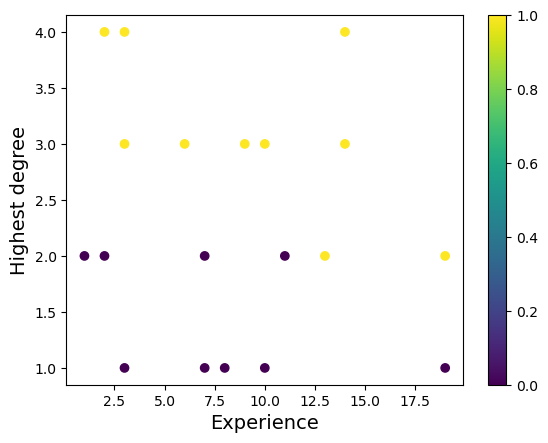

In [3]:
# Plot Experience versus Highest degree:
plt.scatter(data['Experience / years'], data['Highest degree'], c = data['Permanent contract?'])
plt.colorbar() # The color bar help us know which sample belongs to class 0 or 1
plt.xlabel('Experience', fontsize = 14)
plt.ylabel('Highest degree', fontsize = 14);

In [4]:
# Let's define the features and target
X = data.drop(['Permanent contract?'], axis = 1)
y = data['Permanent contract?']

In [5]:
# Split the data into training (70%) and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((13, 3), (6, 3), (13,), (6,))

In [6]:
# preprocess the features
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)


In [7]:
# train the logistic regression model (use default hyperparameters!)
lr = LogisticRegression()
lr.fit(X_train_s, y_train)

LogisticRegression()

In [8]:
# check the parameters of the trained classifier
# 'Age', 'Experience / years', 'Highest degree' (same order as in data)
lr.coef_ # w1, w2 and w3


array([[0.06611235, 0.48181227, 1.60622054]])

In [9]:
# check the bias
lr.intercept_ # w0

array([0.23270645])

In [10]:
# Perform predictions on the test set using the trained model. Compare the predictions with the true values (=y_test)
predictions_lr = lr.predict(X_test_s) # Note: get probabilities instead of classes by using .predict_proba(X_test_s)
predictions_lr

array([1, 0, 1, 0, 1, 0])

In [11]:
lr.predict_proba(X_test_s)

array([[0.49878991, 0.50121009],
       [0.87982445, 0.12017555],
       [0.08418575, 0.91581425],
       [0.74623822, 0.25376178],
       [0.27567366, 0.72432634],
       [0.87628704, 0.12371296]])

In [12]:
y_test.values # check the true classes for the test set

array([1, 0, 1, 0, 1, 0])

In [13]:
# Calculate precision, recall, F1 score, accuracy
report = classification_report(y_test, predictions_lr)
print(report)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         3
           1       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



In [14]:
# show the confusion matrix for the test set
conf_mat = confusion_matrix(y_test, predictions_lr)
conf_mat

array([[3, 0],
       [0, 3]])

<Br><Br>
#### Homework
<Br><Br>

In [15]:
# Calculate manually (using preprocessed coordinates and the classifier parameters) the probability for 
# the prediction of class +1 for the first 3 samples of the training set used in the cells above.
# Compare your manually calculated probabilities with those obtained by the .predict_proba() method.
# Note: after training the classifier lr, you can write 'lr.predict_proba(mysamples)' to get probabilities
# for both classes (the left column will be for class -1, the right one for class +1)
# 
# Tip: You can use the function below for calculating your manual probability (just uncomment the lines below)
def manual_probability(sample, w1, w2, w3, w0):
    """
    Calculate the sigmoid (= probability for class +1) for a sample with three features
    """
    w = [w1,w2,w3]
    score = np.dot(sample, w) + w0
    sigmoid = np.exp(score) / (1 + np.exp(score))
    return sigmoid

<Br><Br>
# 2) Three-class classification via Logistic regression and SVM
<Br><Br>

In [16]:
# Import the csv file and check its content
#Note: The target encoding is: 0 (Temporary contract) or 1 (Permanent contract)
data = pd.read_csv("iris_dataset.csv")
data

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [17]:
le = LabelEncoder() # instantiate the label encoder object
classes = le.fit_transform(data['species']) # convert text (from the column 'species') to numbers (or classes)
classes # check the new classes (not yet implemented in the dataframe!)

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [18]:
# Which species (or text) correspond to which class?
le.classes_ # attribute .classes_ shows the ordering of classes: 0, 1, 2, ... (e.g., 'setosa' is class 0)

array(['setosa', 'versicolor', 'virginica'], dtype=object)

In [19]:
data['class'] = classes # create a new column in the pandas dataframe data
data # check the dataframe

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,class
0,5.1,3.5,1.4,0.2,setosa,0
1,4.9,3.0,1.4,0.2,setosa,0
2,4.7,3.2,1.3,0.2,setosa,0
3,4.6,3.1,1.5,0.2,setosa,0
4,5.0,3.6,1.4,0.2,setosa,0
...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica,2
146,6.3,2.5,5.0,1.9,virginica,2
147,6.5,3.0,5.2,2.0,virginica,2
148,6.2,3.4,5.4,2.3,virginica,2


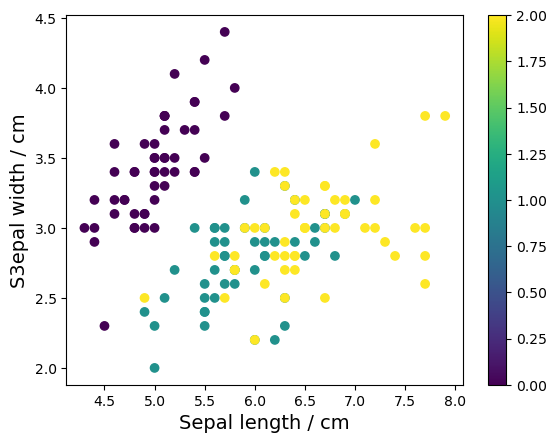

In [20]:
# Plot sepal length versus sepal width and color each sample according to its class (also show a color bar)
plt.scatter(data['sepal length (cm)'], data['sepal width (cm)'], c=data['class'])
plt.colorbar() # The color bar help us know which sample belongs to class 0, 1 or 2
plt.xlabel('Sepal length / cm', fontsize = 14)
plt.ylabel('S3epal width / cm', fontsize = 14);

#### Let's train classifiers using all four features and one target property (= the class)

In [21]:
# Define your features (X) and target (y)

    # Your code here

X = data.drop(['species', 'class'], axis = 1)
y = data['class']


In [22]:
# Split the data into training (40%) and test set
# NOTE: In general we use 70-80% for the training set, but we used only 40% in this exercise to have
# a poorer model and get a more diverse confusion matrix and non-unity metrics, otherwise predictions are always perfect!
# This 3-class classification is too easy for both the logistic regression and the SVC!

    # Your code here
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.4, random_state = 42)
X_train.shape,  X_test.shape,y_train.shape,  y_test.shape


((90, 4), (60, 4), (90,), (60,))

In [23]:
# preprocess the features

    # Your code here
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)



In [24]:
# Create (or instantiate) two different models: logistic regression and SVC (use default hyperparameters!)

    # Your code here
lr = LogisticRegression()
svc = SVC()

In [25]:
# Train both your models

    # Your code here

lr.fit(X_train_s, y_train)
svc.fit(X_train_s, y_train)

SVC()

In [26]:
# perform predictions on the preprocessed test set (name them predictions_lr and predictions_svc)
    
    # Your code here
predictions_lr = lr.predict(X_test_s)
predictions_svc = svc.predict(X_test_s)



In [27]:
# Print the classification reports
report_lr = classification_report(y_test, predictions_lr)
report_svc = classification_report(y_test, predictions_svc)
print('Model = Logistic regression:\n')
print(report_lr)
print('Model = Support Vector Classifier:\n')
print(report_svc)

Model = Logistic regression:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       0.95      1.00      0.97        19
           2       1.00      0.94      0.97        18

    accuracy                           0.98        60
   macro avg       0.98      0.98      0.98        60
weighted avg       0.98      0.98      0.98        60

Model = Support Vector Classifier:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       0.95      1.00      0.97        19
           2       1.00      0.94      0.97        18

    accuracy                           0.98        60
   macro avg       0.98      0.98      0.98        60
weighted avg       0.98      0.98      0.98        60



In [28]:
# Show the confusion matrix for the logistic regression predictions
cm_lr = confusion_matrix(y_test, predictions_lr)
cm_lr

array([[23,  0,  0],
       [ 0, 19,  0],
       [ 0,  1, 17]])

In [29]:
# Show the confusion matrix for the SVC predictions
cm_svc = confusion_matrix(y_test, predictions_svc)
cm_svc

array([[23,  0,  0],
       [ 0, 19,  0],
       [ 0,  1, 17]])

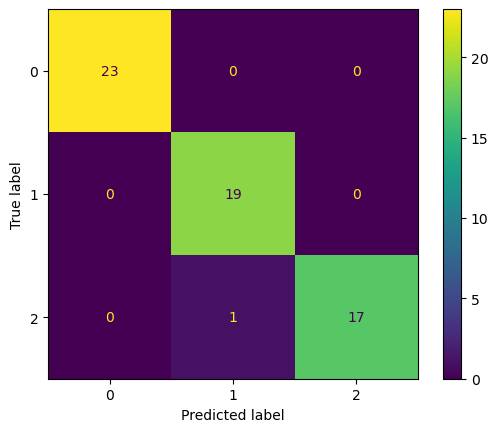

In [30]:
# Make a nice plot of the confusion matrix for the SVC model (the object name used below is svc: change it if needed)
disp = ConfusionMatrixDisplay(cm_svc, display_labels=svc.classes_)
disp.plot();

<Br><Br>
#### Homework
<Br><Br>

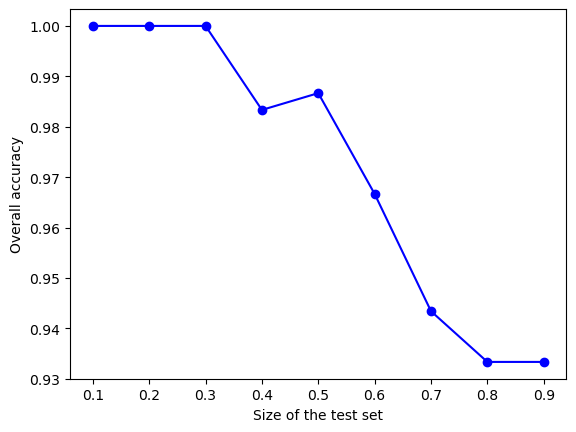

In [31]:
# How good or bad do the predictions get if we use 10%, 20%, ..., up to to 90% of the samples for the test set?
# Show in a simple plot what happens with the overall accuracy for e.g. a logistic regression model when different
# test set sizes are used.
# Tip: use the .score() method of the trained classifier object to calculate the overall accuracy
# e.g., overall_accuracy = lr.score(X_test_s, y_test). You can use the function below.

def get_accuracy(size_test_set):
    
    # import the data

        # Your code here
    data = pd.read_csv("iris_dataset.csv")
    
    # encode the species column to get numeric classes

        # Your code here
    le = LabelEncoder()
    classes = le.fit_transform(data['species'])
    data['class'] = classes
    
    # define features (X) and target (y)

        # Your code here
    X = data.drop(['species', 'class'], axis = 1)
    y = data['class']
    
    # split the dataset
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=size_test_set, random_state=42)
    
    # preprocess the features

        # Your code here
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)
    
    # train the model

        # Your code here
    lr = LogisticRegression()
    lr.fit(X_train_s, y_train)
    
    # get the overall accuracy (predictions are performed internally in the .score() method

        # Your code here  
    overall_accuracy = lr.score(X_test_s, y_test)
    
    return overall_accuracy


# Run the classification for different test set sizes, save accuracies
accuracies = []
test_sizes = np.linspace(0.1, 0.9, num=9) # 0.1, 0.2, 0.3, ..., 0.9
for test_size in test_sizes:
    acc = get_accuracy(test_size)
    accuracies.append(acc)


# plot the results
plt.plot(test_sizes, accuracies, '-bo')
plt.xlabel('Size of the test set')
plt.ylabel('Overall accuracy');

<Br><Br>
# 3) Repeat the three-class classification for the logistic regression using a 5-fold CV to get the average accuracy. 
<Br><Br>

In [32]:
# import the iris dataset
   
   # Your code here
data = pd.read_csv("iris_dataset.csv")

# randomize 100% of the data (as the cross_val_predict function below does not do that,
# unless a KFold object as explicitly used as argument for the cv parameter
data = data.sample(frac = 1, random_state = 42) # use a random state to compare different K values  

# encode the species column to get numeric classes, add the new encoded column to your dataframe

   # Your code here
le = LabelEncoder() # instantiate the label encoder object
classes = le.fit_transform(data['species'])
data['class'] = classes

# define features (X) and target (y)

   # Your code here
X = data.drop(['species', 'class'], axis = 1)
y = data['class']
X_train, y_train, X_test, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)


# Create pipeline (first preprocessing, then model training)
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression())
])

# Get cross-validated predictions (X and y are automatically splitted into folds with training and test sets)
# y_pred below contains all predictions done in 5-fold CV. 
# Note: cross_val_score() could be imported and used to get performance on individual folds.
y_pred = cross_val_predict(pipeline, X, y, cv = 5)

# Calculate the overall accuracy using predictions from ALL folds
overall_accuracy = accuracy_score(y, y_pred)

# Print the results on the screen
print(f'The final accuracy using 5-fold CV is {overall_accuracy}')

The final accuracy using 5-fold CV is 0.9533333333333334


<Br><Br>
#### Homework
<Br><Br>

In [33]:
# Define a function with the code above (and using the number of CV folds 'K' as the only parameter) to
# calculate the overall accuracy for any integer value of K between 3 and 10. What is the best K?

def get_CV_accuracy(K):

    # Your code here
    data = pd.read_csv("iris_dataset.csv")

    # randomize 100% of the data (as the cross_val_predict function below does not do that,
    # unless a KFold object as explicitly used as argument for the cv parameter
    data = data.sample(frac = 1, random_state = 42) # use a random state to compare different K values  
    
    # encode the species column to get numeric classes, add the new encoded column to your dataframe
    
       # Your code here
    le = LabelEncoder() # instantiate the label encoder object
    classes = le.fit_transform(data['species'])
    data['class'] = classes
    
    # define features (X) and target (y)
    
       # Your code here
    X = data.drop(['species', 'class'], axis = 1)
    y = data['class']
    X_train, y_train, X_test, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)
    
    
    # Create pipeline (first preprocessing, then model training)
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('lr', LogisticRegression())
    ])
    
    y_pred = cross_val_predict(pipeline, X, y, cv = K)

    # Your code here
    overall_accuracy = accuracy_score(y, y_pred)
    
    
    return overall_accuracy

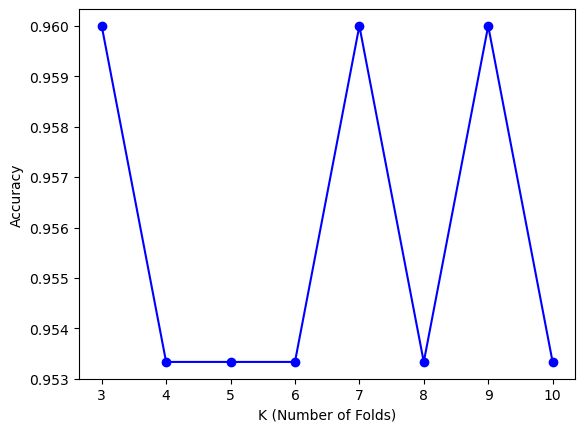

In [34]:
# Calculate the accuracy for the possible K values and plot the results
accuracies = []
K_values = [item for item in range(3,11)] # K_values = [3, 4, ..., 10]
for K in K_values:  
    acc = get_CV_accuracy(K)
    accuracies.append(acc)

plt.plot(K_values, accuracies, '-bo')
plt.xlabel('K (Number of Folds)')
plt.ylabel('Accuracy');